In [1]:
from huggingface_hub import hf_hub_download
from ultralytics import YOLO

# Download trained State Farm model
weights_path = hf_hub_download(
    repo_id="Safe-Drive-TN/State-farm-detection",
    filename="weights/best.pt"
)

# Load trained model
external_model = YOLO(weights_path)

print("Model downloaded successfully!")
print("Class names:", external_model.names)

/home/js/Coursework/distracted-driver-detection/driver-detection-env/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/home/js/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


Model downloaded successfully!
Class names: {0: 'c0', 1: 'c1', 2: 'c2', 3: 'c3', 4: 'c4', 5: 'c5', 6: 'c6', 7: 'c7', 8: 'c8', 9: 'c9'}


## 2. Evaluate External Pretrained Model on Our Validation Data

Load our existing driver-independent validation split.

- Validation images: 3,603
- Validation drivers: 4
- Classes: c0–c9
- Use the externally pretrained YOLO model
- No additional training

Validation images: 3603
Validation drivers: 4
Driver IDs: ['p014', 'p016', 'p047', 'p075']

External model: classify
Classes: {0: 'c0', 1: 'c1', 2: 'c2', 3: 'c3', 4: 'c4', 5: 'c5', 6: 'c6', 7: 'c7', 8: 'c8', 9: 'c9'}

All validation images found!

Running inference...
Processed 3603/3603 images

Inference completed!
Images processed: 3603

EXTERNAL YOLOv8 — VALIDATION RESULTS
Accuracy: 0.9972 (99.72%)
Macro-F1: 0.9971 (99.71%)

Correct predictions: 3593
Incorrect predictions: 10

Total inference time: 6.85 seconds
Average time per image: 0.0019 seconds

PER-CLASS CLASSIFICATION REPORT
              precision    recall  f1-score   support

          c0       1.00      1.00      1.00       372
          c1       0.99      1.00      1.00       377
          c2       1.00      0.99      1.00       367
          c3       1.00      1.00      1.00       393
          c4       1.00      0.99      1.00       378
          c5       1.00      1.00      1.00       372
          c6       1.00      

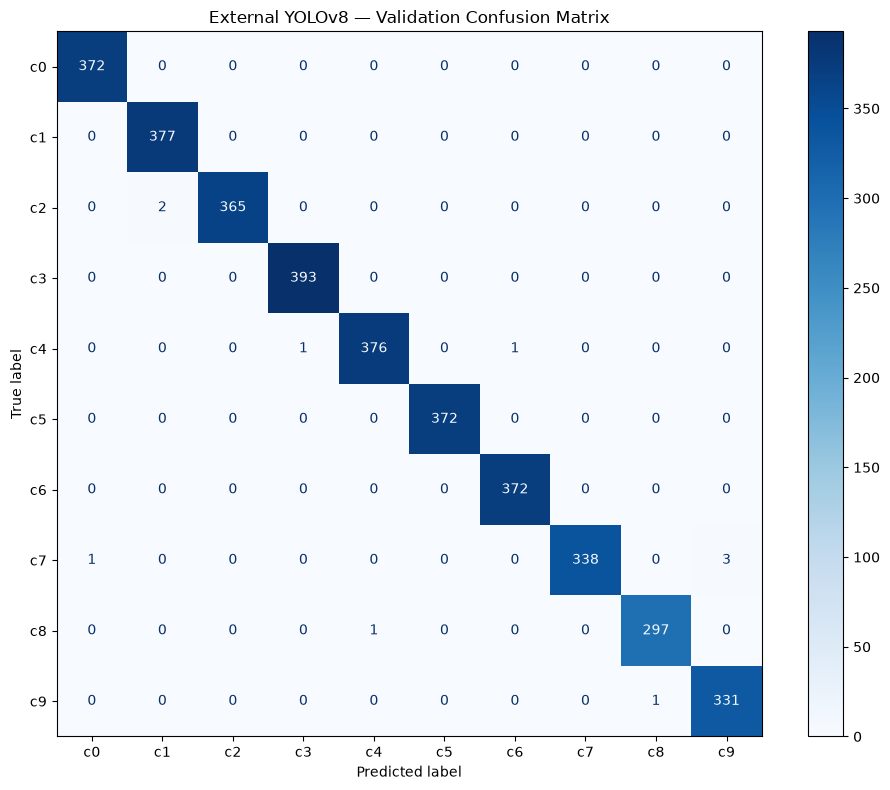

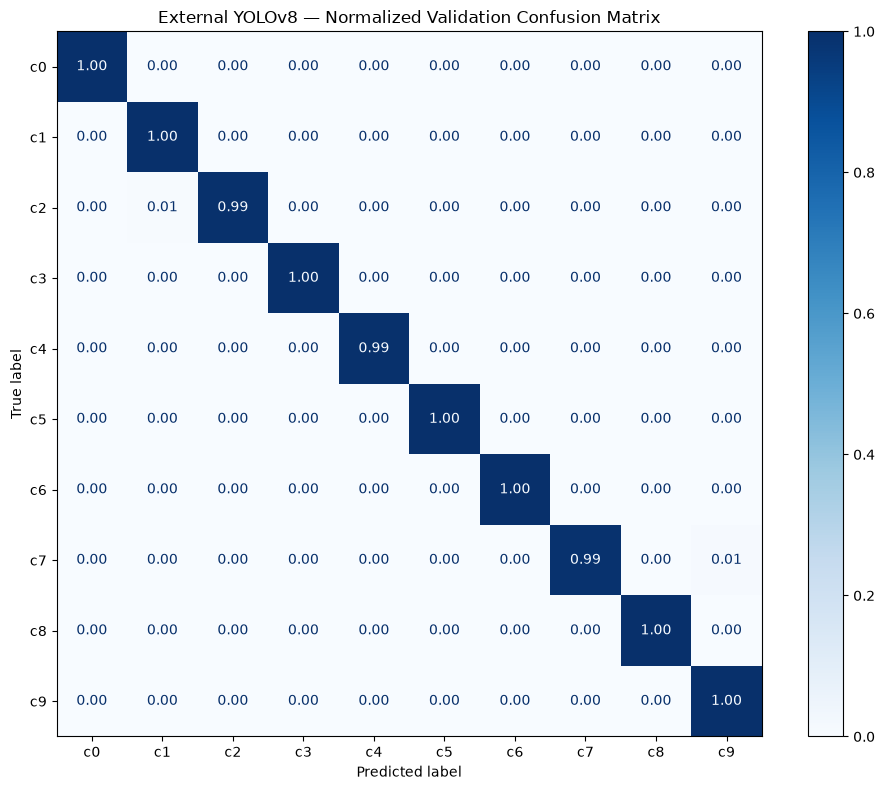


RESULTS SAVED SUCCESSFULLY
Directory: ../results/deep_learning/driver_based/external_pretrained/yolov8


In [3]:
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import json

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. LOAD OUR VALIDATION DATASET
# ============================================================

ROOT = Path("..")

val_df = pd.read_csv(
    ROOT / "data/splits/driver_based/val.csv"
).reset_index(drop=True)

image_root = ROOT / "data/raw/imgs/train"

assert len(val_df) == 3603
assert val_df["subject"].nunique() == 4

print("Validation images:", len(val_df))
print("Validation drivers:", val_df["subject"].nunique())
print("Driver IDs:", sorted(val_df["subject"].unique()))


# ============================================================
# 2. VERIFY EXTERNAL MODEL AND CLASS LABELS
# ============================================================

class_names = [f"c{i}" for i in range(10)]

assert external_model.task == "classify", (
    "Expected a YOLO classification model."
)

assert set(external_model.names.values()) == set(class_names), (
    "External model classes do not match c0-c9."
)

print("\nExternal model:", external_model.task)
print("Classes:", external_model.names)


# ============================================================
# 3. PREPARE IMAGE PATHS
# ============================================================

val_df["filepath"] = val_df.apply(
    lambda row: str(
        (
            image_root /
            row["classname"] /
            row["img"]
        ).resolve()
    ),
    axis=1
)

missing = [
    path
    for path in val_df["filepath"]
    if not Path(path).exists()
]

assert len(missing) == 0, (
    f"Missing images: {len(missing)}"
)

assert val_df["filepath"].is_unique

print("\nAll validation images found!")


# ============================================================
# 4. CONFIGURE INFERENCE
# ============================================================

INFERENCE_BATCH_SIZE = 32
INFERENCE_RESOLUTION = 224

inference_device = (
    0 if torch.cuda.is_available() else "cpu"
)

all_results = []

start_time = time.perf_counter()

print("\nRunning inference...")


# ============================================================
# 5. RUN INFERENCE ON ALL 3,603 IMAGES
# ============================================================

for start in range(0, len(val_df), INFERENCE_BATCH_SIZE):

    end = min(
        start + INFERENCE_BATCH_SIZE,
        len(val_df)
    )

    batch_df = val_df.iloc[start:end]

    image_paths = batch_df["filepath"].tolist()

    # Predict all images in this batch
    predictions = external_model.predict(
        source=image_paths,
        imgsz=INFERENCE_RESOLUTION,
        batch=INFERENCE_BATCH_SIZE,
        device=inference_device,
        verbose=False
    )

    assert len(predictions) == len(batch_df)

    # Store predictions for each validation image
    for row, result in zip(
        batch_df.itertuples(index=False),
        predictions
    ):

        # Verify predictions match the correct image
        assert Path(result.path).resolve() == Path(row.filepath)

        assert result.probs is not None

        predicted_id = int(result.probs.top1)

        predicted_class = result.names[predicted_id]

        confidence = float(result.probs.top1conf)

        all_results.append({
            "subject": row.subject,
            "img": row.img,
            "actual": row.classname,
            "predicted": predicted_class,
            "confidence": confidence,
            "filepath": row.filepath,
            "correct": row.classname == predicted_class
        })

    print(
        f"Processed {end}/{len(val_df)} images",
        end="\r",
        flush=True
    )


# ============================================================
# 6. CALCULATE INFERENCE TIME
# ============================================================

total_inference_time = (
    time.perf_counter() - start_time
)

results_df = pd.DataFrame(all_results)

assert len(results_df) == len(val_df)

print("\n\nInference completed!")
print("Images processed:", len(results_df))


# ============================================================
# 7. CALCULATE OVERALL METRICS
# ============================================================

accuracy = accuracy_score(
    results_df["actual"],
    results_df["predicted"]
)

macro_f1 = f1_score(
    results_df["actual"],
    results_df["predicted"],
    labels=class_names,
    average="macro",
    zero_division=0
)

print("\n" + "=" * 50)
print("EXTERNAL YOLOv8 — VALIDATION RESULTS")
print("=" * 50)

print(f"Accuracy: {accuracy:.4f} ({accuracy:.2%})")
print(f"Macro-F1: {macro_f1:.4f} ({macro_f1:.2%})")

print(
    f"\nCorrect predictions: "
    f"{results_df['correct'].sum()}"
)

print(
    f"Incorrect predictions: "
    f"{(~results_df['correct']).sum()}"
)

print(
    f"\nTotal inference time: "
    f"{total_inference_time:.2f} seconds"
)

print(
    f"Average time per image: "
    f"{total_inference_time / len(results_df):.4f} seconds"
)


# ============================================================
# 8. PER-CLASS PERFORMANCE
# ============================================================

print("\nPER-CLASS CLASSIFICATION REPORT")
print("=" * 50)

print(
    classification_report(
        results_df["actual"],
        results_df["predicted"],
        labels=class_names,
        zero_division=0
    )
)


# ============================================================
# 9. DRIVER-SPECIFIC ACCURACY
# ============================================================

driver_accuracy = (
    results_df
    .groupby("subject")
    .agg(
        images=("correct", "size"),
        accuracy=("correct", "mean")
    )
    .sort_values("accuracy")
)

print("\nACCURACY BY DRIVER")
print("=" * 50)

print(driver_accuracy.to_string())


# ============================================================
# 10. CREATE RESULT DIRECTORIES
# ============================================================

external_exp_dir = (
    ROOT / "results/deep_learning/driver_based/"
    "external_pretrained/yolov8"
)

external_exp_dir.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 11. CONFUSION MATRIX — COUNTS
# ============================================================

fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    results_df["actual"],
    results_df["predicted"],
    labels=class_names,
    display_labels=class_names,
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title(
    "External YOLOv8 — Validation Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    external_exp_dir / "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 12. NORMALIZED CONFUSION MATRIX
# ============================================================

fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    results_df["actual"],
    results_df["predicted"],
    labels=class_names,
    display_labels=class_names,
    normalize="true",
    cmap="Blues",
    values_format=".2f",
    ax=ax
)

ax.set_title(
    "External YOLOv8 — Normalized Validation Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    external_exp_dir / "confusion_matrix_normalized.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 13. SAVE ALL RESULTS
# ============================================================

results_df.to_csv(
    external_exp_dir / "validation_predictions.csv",
    index=False
)

driver_accuracy.to_csv(
    external_exp_dir / "driver_accuracy.csv"
)

summary = {
    "model": "External_Pretrained_YOLOv8",
    "source": "Safe-Drive-TN/State-farm-detection",
    "weights": str(weights_path),
    "validation_images": len(val_df),
    "validation_drivers": sorted(
        val_df["subject"].unique().tolist()
    ),
    "inference_resolution": INFERENCE_RESOLUTION,
    "accuracy": float(accuracy),
    "macro_f1": float(macro_f1),
    "inference_time_seconds": float(total_inference_time),
    "training_overlap_verified": False
}

with open(
    external_exp_dir / "results.json", "w"
) as f:
    json.dump(summary, f, indent=4)

print("\n" + "=" * 50)
print("RESULTS SAVED SUCCESSFULLY")
print("=" * 50)

print("Directory:", external_exp_dir)

In [4]:
# ==========================================
# 1. Display detailed model architecture
# ==========================================

print("YOLOv8n Classification Architecture")
print("=" * 60)

print(external_model.model)


# ==========================================
# 2. Count parameters
# ==========================================

total_params = sum(
    p.numel()
    for p in external_model.model.parameters()
)

print(f"\nTotal parameters: {total_params:,}")


# ==========================================
# 3. Display training configuration
# ==========================================

print("\nOriginal Training Arguments")
print("=" * 60)

train_args = external_model.ckpt.get("train_args", {})

for key in [
    "model",
    "data",
    "epochs",
    "batch",
    "imgsz",
    "pretrained",
    "optimizer",
    "weight_decay",
    "auto_augment",
    "erasing",
    "fliplr",
    "seed"
]:
    print(f"{key}: {train_args.get(key, 'Not recorded')}")

YOLOv8n Classification Architecture
ClassificationModel(
  (model): Sequential(
    (0): Conv(
      (conv): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (1): Conv(
      (conv): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (2): C2f(
      (cv1): Conv(
        (conv): Conv2d(32, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (cv2): Conv(
        (conv): Conv2d(48, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bi